# APRENDIZAJE AUTOMÁTICO Y ANÁLISIS VISUAL DE DATOS
Jaime Rodrigo Roldán Corcelles

## Ejercicio práctico: Algoritmos básicos de clasificación

### EJERCICIOS BÁSICOS
1) (0.5 ptos) Considere el conjunto de muestras {X_v1, y_v1} dado por el siguiente código:

```python
import numpy as np 

rng = np.random.default_rng(seed=5) 
MatCov = np.array([[6, -3], [-3, 3.5]]) 
X_v1 = rng.multivariate_normal([0, 0], MatCov, size=150) 

radios2 = X_v1[:, 0]**2 + X_v1[:, 1]**2 
y_v1 = np.where(radios2 > 1.5, 1, -1) 

pos_neg1 = np.logical_and(X_v1[:, 0] < 0, X_v1[:, 1] < 0) 
pos_neg2 = np.logical_and(
    np.logical_and(X_v1[:, 0] > -2.5, X_v1[:, 0] < -1.5), 
    np.logical_and(X_v1[:, 1] < 2.5, X_v1[:, 1] > 1.25)
) 

y_v1 = y_v1.copy() 
y_v1[pos_neg1 == True] = -1 
y_v1[pos_neg2 == True] = -1
```
a) Entrene una SVM no lineal que ajuste el modelo de manera que ninguna muestra sea mal clasificada.

In [1]:
import matplotlib.pyplot as plt
import numpy as np 
from matplotlib.colors import ListedColormap

# 1. DEFINICIÓN DE LA FUNCIÓN pintar_regiones_decision_v2 (Copiada de los apuntes)
def pintar_regiones_decision_v2(X, y, clasificador, test_idx=None, resolucion=0.02):
    # Configurar los marcadores y el mapa de color
    marcadores = ('s', 'x', 'o', '^', 'v')
    colores = ['red', 'blue', 'lightgreen', 'gray', 'cyan']
    # Asignación de colores a las clases
    cmap = ListedColormap(colores[:len(np.unique(y))])

    # Preparar los márgenes de la superficie de decisión
    x1_min, x1_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    x2_min, x2_max = X[:, 1].min() - 1, X[:, 1].max() + 1

    # Preparar los valores puntuales de la superficie de decisión y el valor del
    # clasifidor para dichos puntos
    xx1, xx2 = np.meshgrid(np.arange(x1_min, x1_max, resolucion),
                           np.arange(x2_min, x2_max, resolucion))

    # Pasamos la entrada a matriz con dos columnas para calcular la salida del
    # clasificador
    # Ojo, hemos puesto predict para usar la terminología estandar de las
    # bibliotecas que vamos a usar
    Z = clasificador.predict(np.array([xx1.reshape(-1), xx2.reshape(-1)]).T)
    # Convertimos la salida predicha al formato adecuado para pintar la
    # superficie
    Z = Z.reshape(xx1.shape)

    # Pintar el contorno de la superficie de decisión y se rellena también
    plt.contourf(xx1, xx2, Z, alpha=0.3, cmap=cmap)
    plt.xlim(xx1.min(), xx1.max())
    plt.ylim(xx2.min(), xx2.max())

    # Pintar todas las muestras en la superficie de decisión
    for idx, cl in enumerate(np.unique(y)):
         plt.scatter(x=X[y == cl, 0],
                     y=X[y == cl, 1],
                     alpha=0.8,
                     c=colores[idx],
                     marker=marcadores[idx],
                     label=cl,
                     edgecolor='black')

    # Marcar las que son muestras de test
    if test_idx:
        # Dibujar todas las muestras
        X_test, y_test = X[test_idx, :], y[test_idx]

        plt.scatter(X_test[:, 0], X_test[:, 1],
                    facecolors='none', edgecolor='black', alpha=1.0,
                    linewidth=1, marker='o',
                    s=100, label='Conjunto de test')

C:\Users\rodri\AppData\Local\Temp\ipykernel_27388\4073114572.py:38: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(x=X[y == cl, 0],


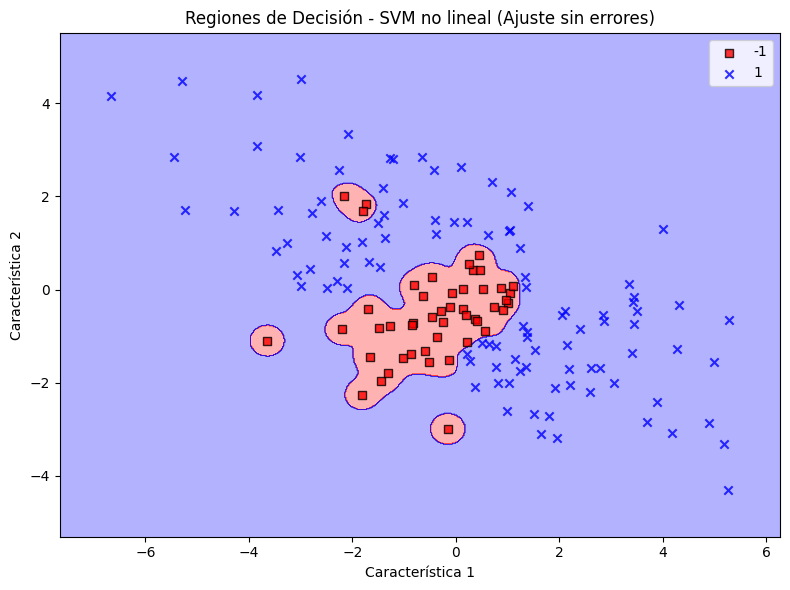

In [2]:

from sklearn.svm import SVC


rng = np.random.default_rng(seed=5) 
MatCov = np.array([[6, -3], [-3, 3.5]]) 
X_v1 = rng.multivariate_normal([0, 0], MatCov, size=150) 

radios2 = X_v1[:, 0]**2 + X_v1[:, 1]**2 
y_v1 = np.where(radios2 > 1.5, 1, -1) 

pos_neg1 = np.logical_and(X_v1[:, 0] < 0, X_v1[:, 1] < 0) 
pos_neg2 = np.logical_and(
    np.logical_and(X_v1[:, 0] > -2.5, X_v1[:, 0] < -1.5), 
    np.logical_and(X_v1[:, 1] < 2.5, X_v1[:, 1] > 1.25)
) 

y_v1 = y_v1.copy() 
y_v1[pos_neg1 == True] = -1 
y_v1[pos_neg2 == True] = -1

# a) Entrenar la SVM no lineal
svm = SVC(kernel='rbf', C=1000, gamma=10, random_state=5)
svm.fit(X_v1, y_v1)

plt.figure(figsize=(8, 6))

# Llamamos a tu función pintar_regiones_decision_v2
pintar_regiones_decision_v2(X=X_v1, y=y_v1, clasificador=svm)

plt.title("Regiones de Decisión - SVM no lineal (Ajuste sin errores)")
plt.xlabel('Característica 1')
plt.ylabel('Característica 2')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()


b) ¿Qué parámetros y valores ha usado? ¿por qué cree que esos parámetros han logrado un ajuste sin error?
* Parámetros usados: Se ha utilizado el núcleo rbf (Radial Basis Function) para que sea no lineal, con un parámetro gamma alto (10) y un parámetro de regularización C también muy alto (1000).
* Se ha logrado un ajuste sin error porque un valor elevado de gamma restringe el área de influencia de cada vector de soporte, creando regiones de decisión muy ceñidas a los datos de entrenamiento. Además, un valor de C tan alto penaliza drásticamente cualquier error de clasificación en el entrenamiento. Esto permite que el modelo "memorice" la posición exacta de las muestras, provocando un sobreajuste perfecto sin errores (0 errores).

c) Escriba un bloque de código que calcule la cantidad de errores de clasificación que comete el modelo.

In [3]:
y_pred_v1 = svm.predict(X_v1)
errores = (y_v1 != y_pred_v1).sum()
print(f"Cantidad de errores de clasificación: {errores}")

Cantidad de errores de clasificación: 0


2) (0.5 ptos) Cargue el conjunto de muestras Iris completo y divídalo en un 30% para test y un 70% para entrenamiento, que usará en todo el ejercicio. <br>
a) Entrene un árbol de decisión utilizando como rasgos los usados en la práctica guiada, es decir, el ancho del pétalo y el largo del pétalo. Utilice la entropía como criterio. Para clasificar una muestra, el árbol debe hacer el menor número de preguntas
y, aunque cometa errores de clasificación, debe ser capaz de distinguir tantas clases de flores como existen en el conjunto de muestras.

In [4]:
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

# Cargar Iris
iris = datasets.load_iris()
X_iris = iris.data[:, [2, 3]]
y_iris = iris.target

# División 70% entrenamiento, 30% test
X_train_iris, X_test_iris, y_train_iris, y_test_iris = train_test_split(
    X_iris, y_iris, test_size=0.3, random_state=5, stratify=y_iris)

# Entrenar árbol de decisión con entropía. 
# Para distinguir 3 clases haciendo el menor número de preguntas, basta con max_depth=2.
arbol_iris = DecisionTreeClassifier(criterion='entropy', max_depth=2, random_state=5)
arbol_iris.fit(X_train_iris, y_train_iris)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",2
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",5
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current 

b) En el árbol del apartado anterior, ¿cuántas preguntas hay que hacer para clasificar una muestra?<br>
Se requiere realizar 2 preguntas como máximo para clasificar cualquier muestra. Al limitar la profundidad del árbol a 2 (max_depth=2), el árbol puede generar hasta 4 nodos hoja, lo cual es suficiente para distinguir las 3 clases existentes en el conjunto de Iris.

c) ¿Qué modelo cree que está menos ajustado, el que acaba de implementar o uno que tenga profundidad 5? Razone su respuesta.<br>
El modelo que acabamos de implementar está menos ajustado. A medida que aumentamos la profundidad, el modelo puede hacer muchas más preguntas para aislar perfectamente cada muestra de entrenamiento, incluso el ruido, aumentando el riesgo de sobreajuste. Una profundidad menor limita la complejidad del árbol, favoreciendo un comportamiento más generalista.

3) (2 ptos) Considere de nuevo el conjunto de datos {X_v1, y_v1} visto en el ejercicio 1. Divida las 150 muestras en un 70% entrenamiento y un 30% test, use semilla aleatoria 5. Use esta división de muestras en todo el ejercicio.
a) Entrene dos árboles de decisión con gini como criterio y semilla aleatoria 5, el árbol A tendrá profundidad máxima de 3 y el B tendrá 6.

In [5]:
import matplotlib.pyplot as plt
from sklearn import tree

# División de las muestras del ejercicio 1
X_train_v1, X_test_v1, y_train_v1, y_test_v1 = train_test_split(
    X_v1, y_v1, test_size=0.3, random_state=5)

# a) Entrenar árboles A y B
arbol_A = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=5)
arbol_B = DecisionTreeClassifier(criterion='gini', max_depth=6, random_state=5)
arbol_A.fit(X_train_v1, y_train_v1)
arbol_B.fit(X_train_v1, y_train_v1)

# Agrupamos para usar la función de pintar regiones de los apuntes
X_entYtest_v1 = np.vstack((X_train_v1, X_test_v1))
y_entYtest_v1 = np.hstack((y_train_v1, y_test_v1))
indices_test = range(len(y_train_v1), len(y_entYtest_v1))

b) Dibuje dos gráficas, una para cada árbol, en las que se muestren las regiones de decisión y se diferencien las muestras de entrenamiento y de test.

C:\Users\rodri\AppData\Local\Temp\ipykernel_27388\4073114572.py:38: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(x=X[y == cl, 0],
C:\Users\rodri\AppData\Local\Temp\ipykernel_27388\4073114572.py:38: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(x=X[y == cl, 0],


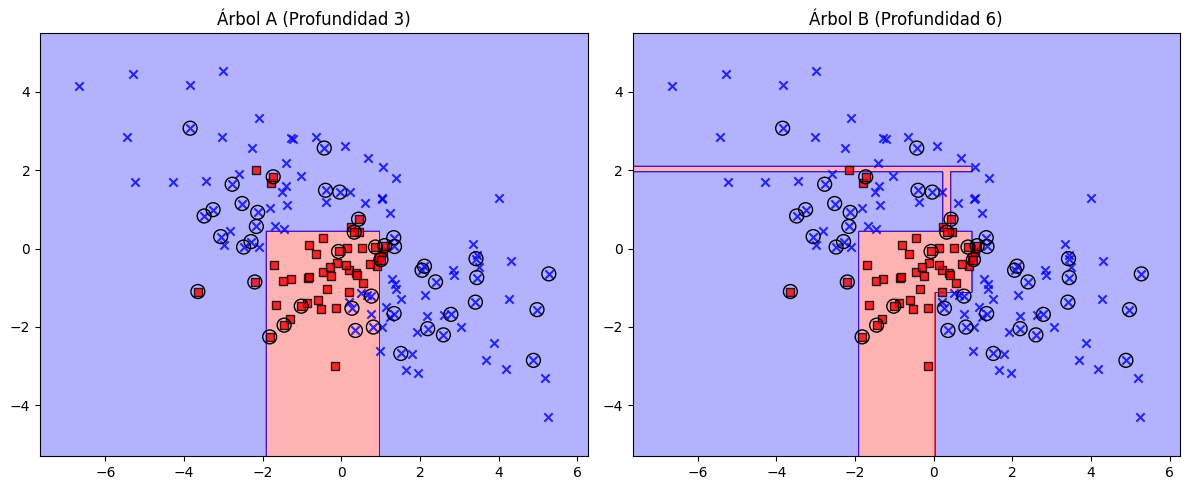

In [6]:

# b) Dibujar regiones de decisión
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
pintar_regiones_decision_v2(X_entYtest_v1, y_entYtest_v1, arbol_A, test_idx=indices_test)
plt.title('Árbol A (Profundidad 3)')

plt.subplot(1, 2, 2)
pintar_regiones_decision_v2(X_entYtest_v1, y_entYtest_v1, arbol_B, test_idx=indices_test)
plt.title('Árbol B (Profundidad 6)')
plt.tight_layout()
plt.show()

c) Dibuje los árboles de preguntas de ambos modelos.

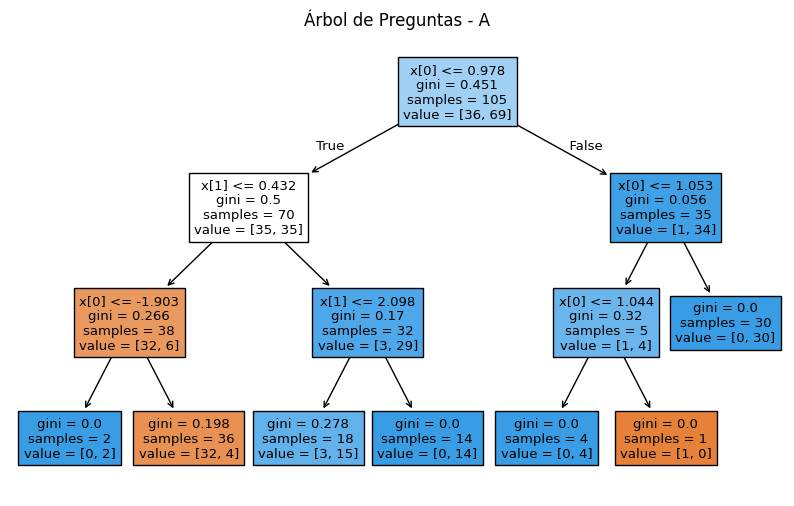

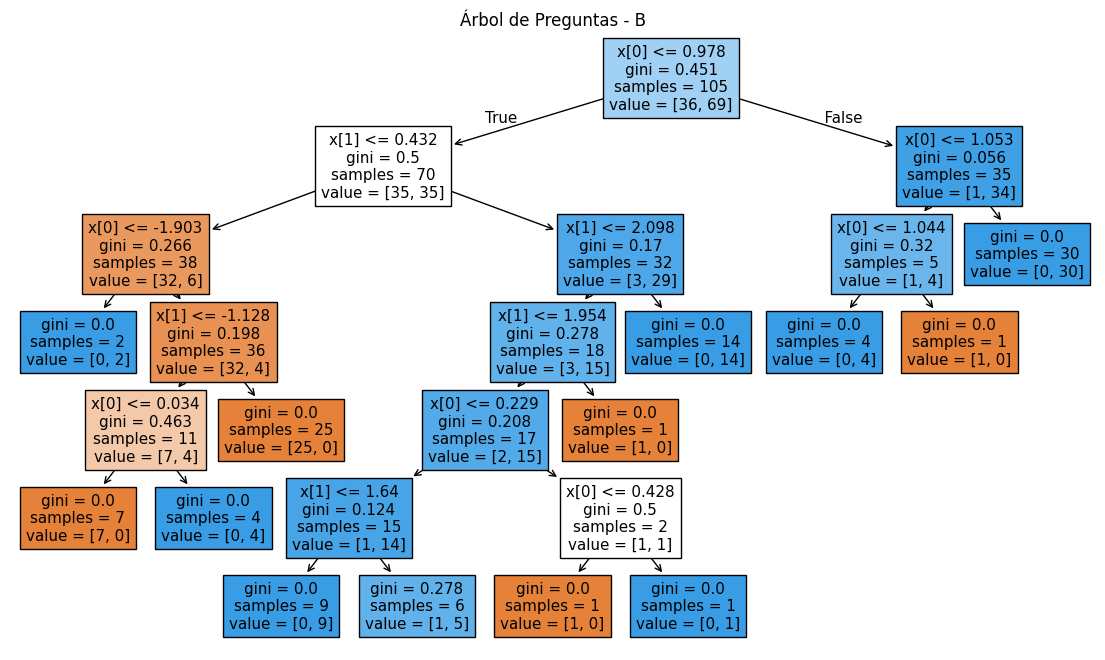

In [7]:

# c) Dibujar los árboles de preguntas
plt.figure(figsize=(10, 6))
tree.plot_tree(arbol_A, filled=True)
plt.title("Árbol de Preguntas - A")
plt.show()

plt.figure(figsize=(14, 8))
tree.plot_tree(arbol_B, filled=True)
plt.title("Árbol de Preguntas - B")
plt.show()

d) Dibuje un gráfico de barras apiladas para comparar el rendimiento en test de ambos árboles. En la primera barra dibuje, para el árbol A, la exactitud en test de color verde y de color rojo el error, hago lo mismo en la segunda barra para el árbol B.

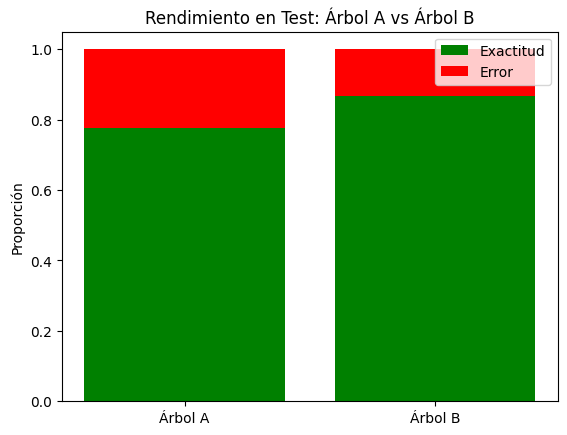

In [8]:
# d) Gráfico de barras apiladas
acc_A = arbol_A.score(X_test_v1, y_test_v1)
acc_B = arbol_B.score(X_test_v1, y_test_v1)
err_A = 1 - acc_A
err_B = 1 - acc_B

etiquetas = ['Árbol A', 'Árbol B']
exactitud = [acc_A, acc_B]
errores = [err_A, err_B]

plt.bar(etiquetas, exactitud, color='green', label='Exactitud')
plt.bar(etiquetas, errores, bottom=exactitud, color='red', label='Error')
plt.ylabel('Proporción')
plt.title('Rendimiento en Test: Árbol A vs Árbol B')
plt.legend()
plt.show()

e) Para saber qué modelo tiene mejor capacidad de generalización, ¿sería necesario conocer el rendimiento en el conjunto entrenamiento?<br>
No, la capacidad de generalización de un modelo se evalúa directamente observando su rendimiento ante datos nunca antes vistos (el conjunto de test).

f) ¿Cuál de los dos árboles generaliza mejor? ¿por qué el otro árbol generaliza peor, diría que tiende al sobreajuste o al subajuste?<br>
El Árbol B generaliza mejor porque obtiene una mayor exactitud al enfrentarse al conjunto de test. Por el contrario, el Árbol A generaliza peor y diría que tiende al subajuste (underfitting). Al limitarle la profundidad máxima a solo 3, el modelo es demasiado simple y no tiene la capacidad suficiente para aprender.

4) (1 pto) Ejecute el siguiente código para generar un conjunto de muestras:
```python
import numpy as np
np.random.seed(15) 
X_v4 = np.random.randn(150, 2) 
pos_Clase1 = np.logical_and(X_v4[:, 0] > 0, X_v4[:, 1] > 0) 
pos_Clase2 = np.logical_and(X_v4[:, 0] < -0.5, X_v4[:, 1] < 0) 

y_v4=np.zeros(X_v4.shape[0]) 
y_v4[pos_Clase1]=1 
y_v4[pos_Clase2]=2
```
Divida las muestras en un 70% para entrenamiento y un 30% para test, úselas en todo el ejercicio.<br>

a) Clasifique las muestras mediante los siguientes modelos predictivos vistos en esta unidad: regresión logística (biblioteca scikit-learn y solver=lbfgs), árboles de decisión y KNN. En aras de la simplicidad, cuando cree los modelos, utilice los valores por defecto en los constructores de los objetos.

In [9]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
import numpy as np

np.random.seed(15)
X_v4 = np.random.randn(150, 2)
pos_Clase1 = np.logical_and(X_v4[:, 0] > 0, X_v4[:, 1] > 0)
pos_Clase2 = np.logical_and(X_v4[:, 0] < -0.5, X_v4[:, 1] < 0)
y_v4 = np.zeros(X_v4.shape[0])
y_v4[pos_Clase1] = 1
y_v4[pos_Clase2] = 2

# División 70/30
X_train_v4, X_test_v4, y_train_v4, y_test_v4 = train_test_split(
    X_v4, y_v4, test_size=0.3, random_state=15)

# Clasificadores
lr_v4 = LogisticRegression(solver='lbfgs')
dt_v4 = DecisionTreeClassifier()
knn_v4 = KNeighborsClassifier()

lr_v4.fit(X_train_v4, y_train_v4)
dt_v4.fit(X_train_v4, y_train_v4)
knn_v4.fit(X_train_v4, y_train_v4)

print(f"Exactitud en test (Regresión Logística): {lr_v4.score(X_test_v4, y_test_v4):.3f}")
print(f"Exactitud en test (Árbol Decisión): {dt_v4.score(X_test_v4, y_test_v4):.3f}")
print(f"Exactitud en test (KNN): {knn_v4.score(X_test_v4, y_test_v4):.3f}")

Exactitud en test (Regresión Logística): 0.756
Exactitud en test (Árbol Decisión): 0.978
Exactitud en test (KNN): 0.956


b) Indique cuál es el peor modelo para clasificar estas muestras. Justifique su respuesta utilizando la medida de rendimiento que estime oportuna.

El peor modelo para clasificar estas muestras es la Regresión Logística. Al revisar la exactitud (accuracy) en el conjunto de test, observamos que el resultado de la regresión logística 0.756 es mucho inferior al del arbol de decisión y KNN 0.978 y 0.956 respectivamente.

c) ¿Por qué el modelo del apartado anterior no se adapta tan bien a las muestras? Apoye su respuesta ilustrándola con las gráficas que crea adecuadas.

La Regresión Logística es un modelo estrictamente lineal. En el código del enunciado, las clases están repartidas por cuadrantes opuestos. Esto crea un problema geométrico en el que es imposible trazar rectas que separen perfectamente a las tres clases sin cometer graves errores. Por el contrario, los Árboles y KNN son algoritmos no lineales que sí logran capturar las fronteras curvadas o delimitadas por cuadrantes

C:\Users\rodri\AppData\Local\Temp\ipykernel_27388\4073114572.py:38: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(x=X[y == cl, 0],
C:\Users\rodri\AppData\Local\Temp\ipykernel_27388\4073114572.py:38: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(x=X[y == cl, 0],
C:\Users\rodri\AppData\Local\Temp\ipykernel_27388\4073114572.py:38: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(x=X[y == cl, 0],


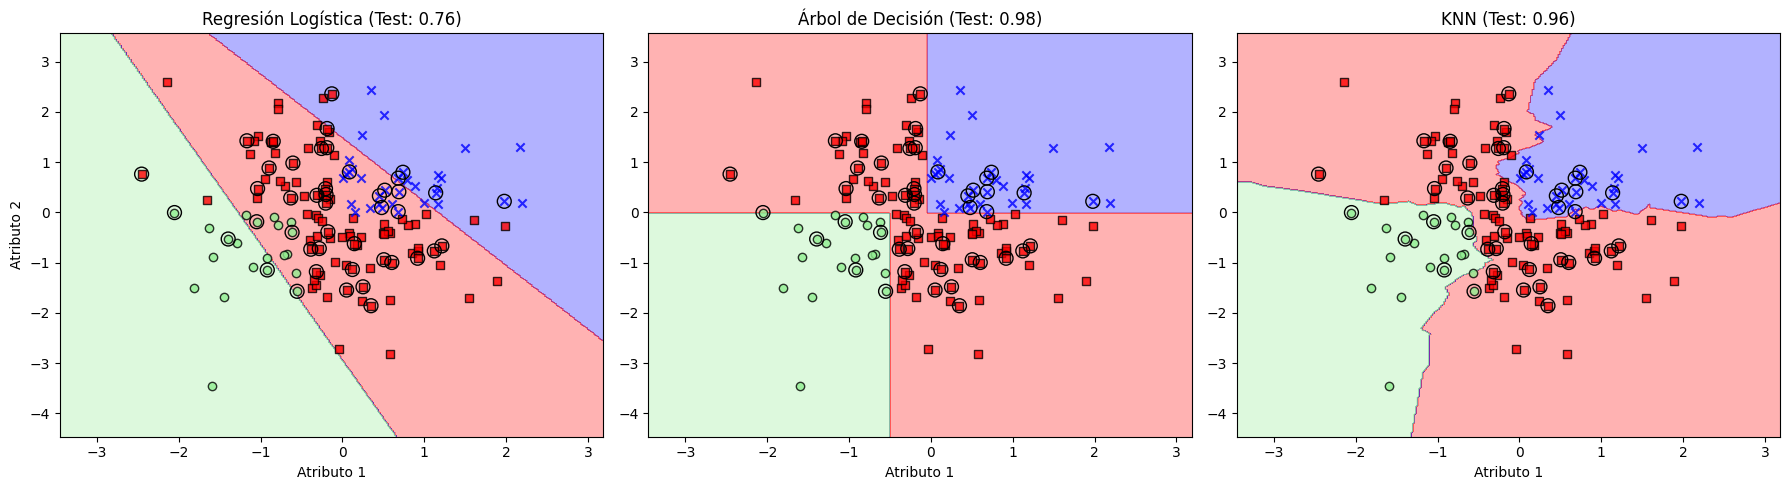

In [ ]:
# 4. Preparar datos combinados para pintar gráficas
X_todo = np.vstack((X_train_v4, X_test_v4))
y_todo = np.hstack((y_train_v4, y_test_v4))
indices_test = range(len(y_train_v4), len(y_todo))


# Creamos una figura ancha  (18 de ancho x 5 de alto)
plt.figure(figsize=(18, 5))

# Gráfica 1: Regresión Logística 
plt.subplot(1, 3, 1)
pintar_regiones_decision_v2(X_todo, y_todo, lr_v4, test_idx=indices_test)
plt.title(f"Regresión Logística (Test: {lr_v4.score(X_test_v4, y_test_v4):.2f})")
plt.xlabel('Atributo 1')
plt.ylabel('Atributo 2')

# Gráfica 2: Árbol de Decisión 
plt.subplot(1, 3, 2) 
pintar_regiones_decision_v2(X_todo, y_todo, dt_v4, test_idx=indices_test)
plt.title(f"Árbol de Decisión (Test: {dt_v4.score(X_test_v4, y_test_v4):.2f})")
plt.xlabel('Atributo 1')

# Gráfica 3: KNN 
plt.subplot(1, 3, 3) 
pintar_regiones_decision_v2(X_todo, y_todo, knn_v4, test_idx=indices_test)
plt.title(f"KNN (Test: {knn_v4.score(X_test_v4, y_test_v4):.2f})")
plt.xlabel('Atributo 1')

# Ajustamos los márgenes para que no se superpongan
plt.tight_layout()
plt.show()

5) (2 ptos) Cargue el conjunto de muestras “winequality-red.csv”, puede usar las siguientes etiquetas para los atributos y clase deseada:
'Acidez', 'Acidez volátil', 'Ácido cítrico', 'Azúcar', 'Cloruros', 'DS libre', 'DS total', 'Densidad', 'pH', 'Sulfitos', 'Alcohol', 'Calidad'
Divida el conjunto de muestras en un 70% para entrenamiento y un 30% para test, después escale las muestras. Use estas muestras en el resto del ejercicio.

a) ¿Cuántas calidades de vinos hay en el conjunto de muestras? ¿cuál es la calidad mínima? ¿y la máxima?

In [11]:
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Etiquetas proporcionadas en el enunciado
etiquetas = ['Acidez', 'Acidez volátil', 'Ácido cítrico', 'Azúcar', 'Cloruros', 
             'DS libre', 'DS total', 'Densidad', 'pH', 'Sulfitos', 'Alcohol', 'Calidad']

# a) Cargar datos asignando los nombres de las columnas (suponiendo que no hay cabecera y el separador es coma)
df_wine = pd.read_csv("data/winequality-red.csv", sep=",", header=None, names=etiquetas)

X_wine = df_wine.drop('Calidad', axis=1).values
y_wine = df_wine['Calidad'].values

calidades_unicas = np.unique(y_wine)
print(f"a) Hay {len(calidades_unicas)} calidades de vino en el conjunto.")
print(f"Calidad mínima: {calidades_unicas.min()}, Calidad máxima: {calidades_unicas.max()}")

# División 70% entrenamiento y 30% test, y escalado
X_train_w, X_test_w, y_train_w, y_test_w = train_test_split(
    X_wine, y_wine, test_size=0.3, random_state=5)

sc = StandardScaler()
X_train_w_std = sc.fit_transform(X_train_w)
X_test_w_std = sc.transform(X_test_w)

a) Hay 6 calidades de vino en el conjunto.
Calidad mínima: 3, Calidad máxima: 8


b) Clasifique las muestras mediante máquinas de vectores de soporte no lineal con 𝑔𝑎𝑚𝑚𝑎=1 y pruebe los siguientes valores de 𝐶={10<sup>-2</sup>,10<sup>-1</sup>,1,10,10<sup>2</sup>}. En una gráfica con la exactitud en el eje vertical y los valores de C en el horizontal, dibuje una curva para la exactitud en el conjunto de test y otra curva para la exactitud en el conjunto de entrenamiento.

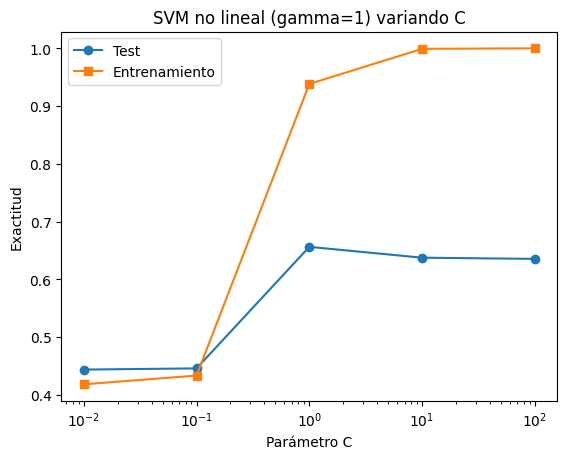

In [12]:
# b) Máquinas de vectores de soporte variando C
valores_C = [1e-2, 1e-1, 1, 10, 100]
acc_train_c = []
acc_test_c = []

for c in valores_C:
    svm_w = SVC(kernel='rbf', gamma=1, C=c, random_state=5)
    svm_w.fit(X_train_w_std, y_train_w)
    acc_train_c.append(svm_w.score(X_train_w_std, y_train_w))
    acc_test_c.append(svm_w.score(X_test_w_std, y_test_w))

plt.figure()
plt.plot(valores_C, acc_test_c, label='Test', marker='o')
plt.plot(valores_C, acc_train_c, label='Entrenamiento', marker='s')
plt.xscale('log')
plt.xlabel('Parámetro C')
plt.ylabel('Exactitud')
plt.title('SVM no lineal (gamma=1) variando C')
plt.legend()
plt.show()

c) Dibuje dos diagramas de sectores, cada sector representará la cantidad de muestras que pertenecen a cada clase. En el primer diagrama represente las predicciones en el conjunto de test de una máquina de vectores de soporte no lineal con 𝑔𝑎𝑚𝑚𝑎=1 y 𝐶=10<sup>2</sup>, en el segundo diagrama represente las clases deseadas del conjunto de test. En ambos casos dibuje la leyenda, separe el sector más numeroso del resto del diagrama, gire 30º el diagrama y utilice el parámetro labeldistance=None en la función pie.

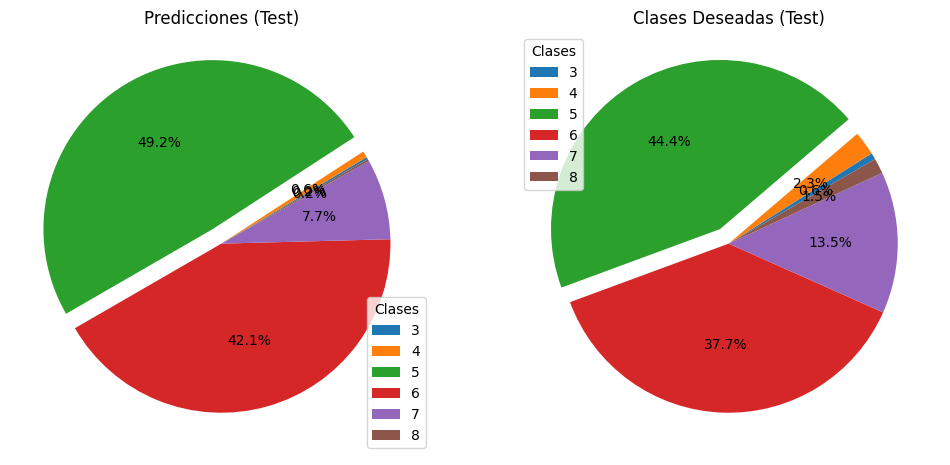

In [13]:

# c) Diagramas de sectores para C=10^2
svm_final = SVC(kernel='rbf', gamma=1, C=100, random_state=5)
svm_final.fit(X_train_w_std, y_train_w)
y_pred_w = svm_final.predict(X_test_w_std)

# Cálculo de frecuencias para el pie chart
clases_pred, conteos_pred = np.unique(y_pred_w, return_counts=True)
clases_test, conteos_test = np.unique(y_test_w, return_counts=True)

# Separar el sector más numeroso
explode_pred = [0.1 if count == conteos_pred.max() else 0 for count in conteos_pred]
explode_test = [0.1 if count == conteos_test.max() else 0 for count in conteos_test]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

ax1.pie(conteos_pred, explode=explode_pred, labels=clases_pred, 
        autopct='%1.1f%%', startangle=30, labeldistance=None)
ax1.set_title("Predicciones (Test)")
ax1.legend(clases_pred, title="Clases", loc="best")

ax2.pie(conteos_test, explode=explode_test, labels=clases_test, 
        autopct='%1.1f%%', startangle=30, labeldistance=None)
ax2.set_title("Clases Deseadas (Test)")
ax2.legend(clases_test, title="Clases", loc="best")

plt.show()

d) ¿Clasifica bien las muestras? Comente los resultados que observa en los diagramas del apartado anterior.

No clasifica bien, se ha producido sobreajuste. 
En los gráficos se observa que el modelo es incapaz de reconocer las clases minoritarias (calidades 3, 4 y 8), haciéndolas casi desaparecer en sus predicciones. Ante la duda, el modelo va a lo seguro y asigna esas muestras a las clases mayoritarias (5 y 6), inflando sus porcentajes muy por encima de la distribución real. Por eso las clases mayoritarias aumentan su porcentaje aproximadamente un 5% cada una en la predicción. 

### EJERCICIO AVANZADO
6) (2 ptos) Cargue el conjunto de datos Breast Cancer que viene incorporado en sklearn ejecutando el siguiente código (en “X” estarán los rasgos y en “y” las salidas deseadas): from sklearn.datasets import load_breast_cancer data_breast_cancer = load_breast_cancer() X=data_breast_cancer['data'] y=data_breast_cancer['target']
Haga una división en conjuntos de entrenamiento (70%) y test (30%), que usará en todo el ejercicio.

a) Entrene diferentes árboles de decisión, usando el criterio de Gini y el criterio de la entropía. Pruebe con valores del número máximo de nodos hoja (max_leaf_nodes) desde 2 hasta 20, ambos inclusive. Mida la exactitud (accuracy) para los conjuntos de entrenamiento y test. Una vez hechas todas estas pruebas, genere una única figura en la que se puedan comparar los resultados obtenidos. El eje horizontal será el número máximo de nodos hoja, y el eje vertical la exactitud. Debe haber cuatro series de datos, según el criterio utilizado y según el conjunto de datos usado (entrenamiento o test).

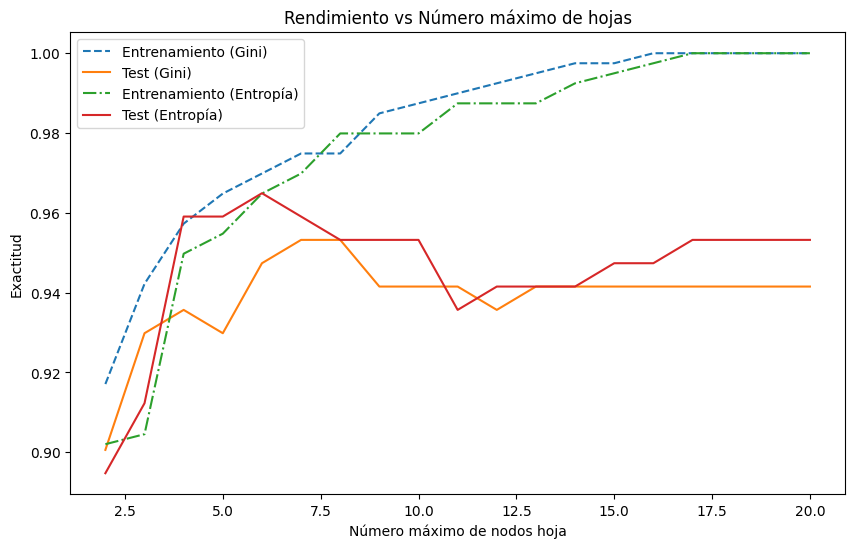

In [14]:
from sklearn.datasets import load_breast_cancer

data_bc = load_breast_cancer()
X_bc = data_bc['data']
y_bc = data_bc['target']

X_train_bc, X_test_bc, y_train_bc, y_test_bc = train_test_split(
    X_bc, y_bc, test_size=0.3, random_state=5)

# a) Árboles variando max_leaf_nodes (2 a 20)
max_hojas = range(2, 21)
acc_gini_tr, acc_gini_te = [], []
acc_ent_tr, acc_ent_te = [], []

for hojas in max_hojas:
    # Gini
    dt_gini = DecisionTreeClassifier(criterion='gini', max_leaf_nodes=hojas, random_state=5)
    dt_gini.fit(X_train_bc, y_train_bc)
    acc_gini_tr.append(dt_gini.score(X_train_bc, y_train_bc))
    acc_gini_te.append(dt_gini.score(X_test_bc, y_test_bc))
    
    # Entropía
    dt_ent = DecisionTreeClassifier(criterion='entropy', max_leaf_nodes=hojas, random_state=5)
    dt_ent.fit(X_train_bc, y_train_bc)
    acc_ent_tr.append(dt_ent.score(X_train_bc, y_train_bc))
    acc_ent_te.append(dt_ent.score(X_test_bc, y_test_bc))

plt.figure(figsize=(10,6))
plt.plot(max_hojas, acc_gini_tr, label='Entrenamiento (Gini)', linestyle='--')
plt.plot(max_hojas, acc_gini_te, label='Test (Gini)')
plt.plot(max_hojas, acc_ent_tr, label='Entrenamiento (Entropía)', linestyle='-.')
plt.plot(max_hojas, acc_ent_te, label='Test (Entropía)')
plt.xlabel('Número máximo de nodos hoja')
plt.ylabel('Exactitud')
plt.title('Rendimiento vs Número máximo de hojas')
plt.legend()
plt.show()

b) ¿El ajuste a los datos de entrenamiento aumenta o disminuye conforme aumenta el valor del número máximo de hojas?

Conforme aumenta el número de hojas máximas, la exactitud sobre los datos de entrenamiento aumenta.

c) ¿Cree que mejora o empeora la capacidad de generalización del modelo al aumentar el valor del número máximo de hojas? Razone sus respuestas.

La capacidad de generalización al inicio mejora  pero pronto tiende a empeorar. Finalmente observamos que más o menos se estabiliza. A medida que permitimos más nodos hojas, el árbol captura no solo patrones útiles sino también ruido particular de las muestras de entrenamiento, llevando al sobreajuste y empeorando la exactitud en el test.

d) Repita el apartado a, pero en este caso variando el parámetro del mínimo número de muestras exigido para dividir un nodo (min_samples_split). Pruebe con 80 valores igualmente espaciados de min_samples_split, desde 0.01 hasta 1.¡

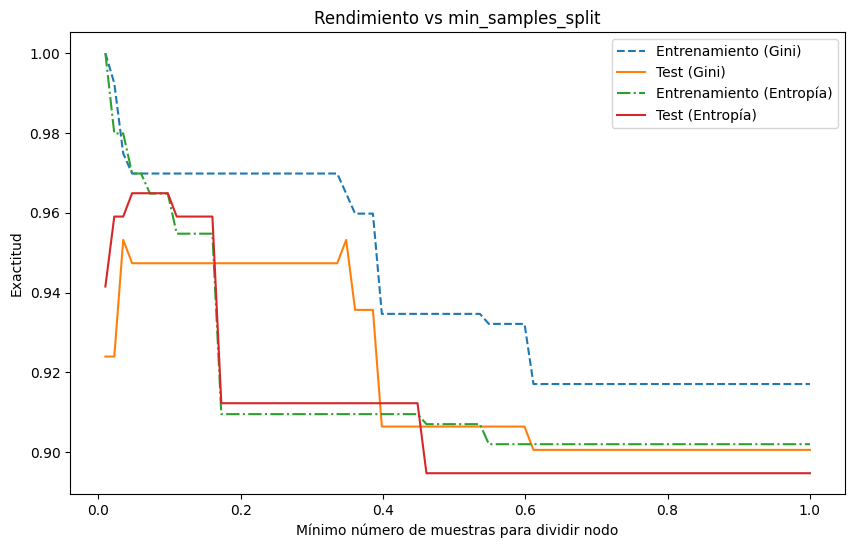

In [15]:
min_split_vals = np.linspace(0.01, 1.0, 80)
acc_gini_tr_s, acc_gini_te_s = [], []
acc_ent_tr_s, acc_ent_te_s = [], []

for split in min_split_vals:
    # Gini
    dt_gini_s = DecisionTreeClassifier(criterion='gini', min_samples_split=split, random_state=5)
    dt_gini_s.fit(X_train_bc, y_train_bc)
    acc_gini_tr_s.append(dt_gini_s.score(X_train_bc, y_train_bc))
    acc_gini_te_s.append(dt_gini_s.score(X_test_bc, y_test_bc))
    
    # Entropía
    dt_ent_s = DecisionTreeClassifier(criterion='entropy', min_samples_split=split, random_state=5)
    dt_ent_s.fit(X_train_bc, y_train_bc)
    acc_ent_tr_s.append(dt_ent_s.score(X_train_bc, y_train_bc))
    acc_ent_te_s.append(dt_ent_s.score(X_test_bc, y_test_bc))

plt.figure(figsize=(10,6))
plt.plot(min_split_vals, acc_gini_tr_s, label='Entrenamiento (Gini)', linestyle='--')
plt.plot(min_split_vals, acc_gini_te_s, label='Test (Gini)')
plt.plot(min_split_vals, acc_ent_tr_s, label='Entrenamiento (Entropía)', linestyle='-.')
plt.plot(min_split_vals, acc_ent_te_s, label='Test (Entropía)')
plt.xlabel('Mínimo número de muestras para dividir nodo')
plt.ylabel('Exactitud')
plt.title('Rendimiento vs min_samples_split')
plt.legend()
plt.show()

e) ¿Existe alguna relación entre los resultados obtenidos en los apartados a y d?

Ambos parámetros hacen exactamente lo opuesto.

Aumentar max_leaf_nodes le da libertad al árbol para crecer más. Esto lo hace más complejo y aumenta el riesgo de que acabe memorizando los datos (sobreajuste).

Aumentar min_samples_split le pone frenos al árbol. Como le exiges tener muchos datos juntos para poder crear una rama nueva, el árbol se queda más simple y pequeño. Esto es útil para evitar el sobreajuste, pero si lo frenas demasiado, el modelo quedará demasiado básico y general (subajuste).

### EJERCICIO EXPERTO
7) (2 ptos) Cargue el conjunto de datos Breast Cancer que viene incorporado en sklearn, como en el ejercicio anterior. Haga una división en conjuntos de entrenamiento (70%) y test (30%), que usará en todo el ejercicio.

a) Entrene diferentes clasificadores de los k vecinos más próximos, usando las siguientes métricas: 'braycurtis', 'canberra', 'chebyshev', 'cityblock', 'correlation', 'cosine', 'euclidean'. Pruebe con valores del número de vecinos más próximos (n_neighbors) desde 1 hasta 40, ambos inclusive. Mida la exactitud (accuracy) para los conjuntos de entrenamiento y test. Una vez hechas todas estas pruebas, genere dos figuras en las que se puedan comparar los resultados obtenidos. Una figura mostrará la exactitud en entrenamiento y la otra figura la exactitud en test. El eje horizontal será el número de vecinos más próximos, y el eje vertical la exactitud. Debe haber siete series de datos en cada figura, según la métrica utilizada.

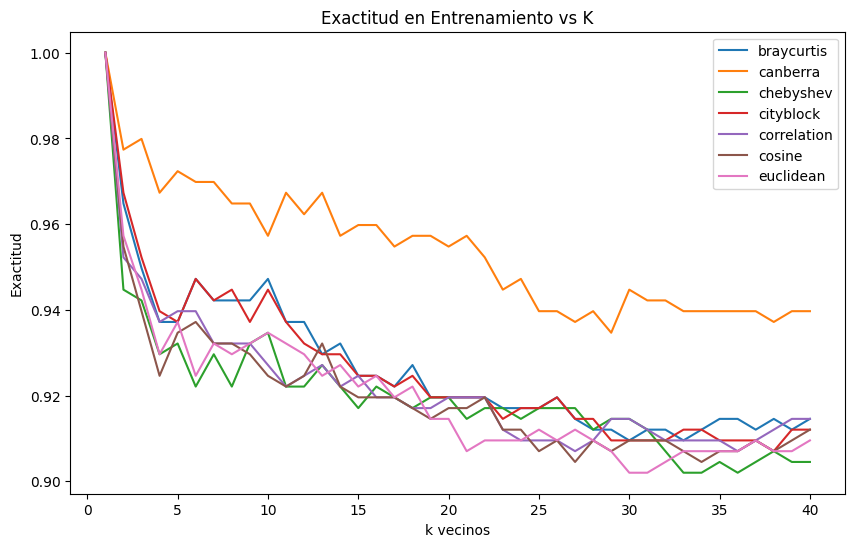

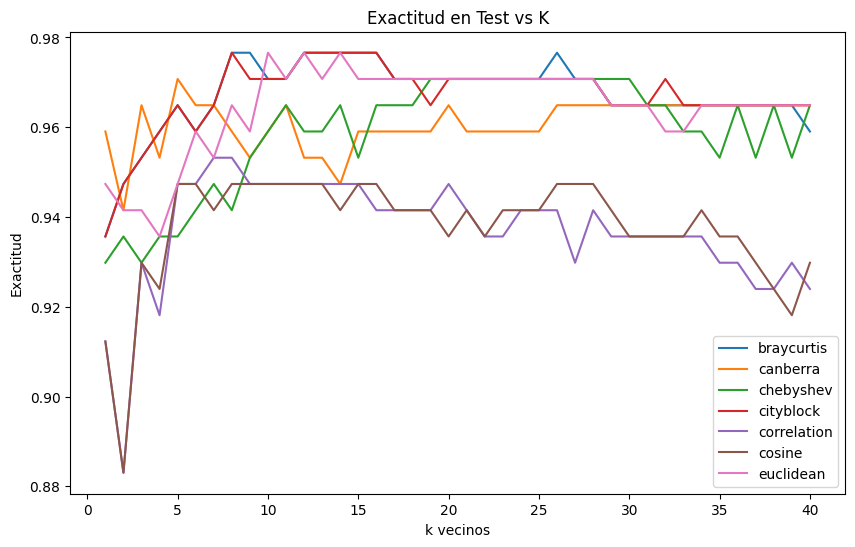

In [16]:
from sklearn.neighbors import KNeighborsClassifier
import matplotlib.pyplot as plt
import numpy as np

metricas = ['braycurtis', 'canberra', 'chebyshev', 'cityblock', 'correlation', 'cosine', 'euclidean']
valores_k = range(1, 41)

fig_train, ax_train = plt.subplots(figsize=(10, 6))
fig_test, ax_test = plt.subplots(figsize=(10, 6))

for metric in metricas:
    acc_tr, acc_te = [], []
    
    for k in valores_k:
        knn_bc = KNeighborsClassifier(n_neighbors=k, metric=metric)
        knn_bc.fit(X_train_bc, y_train_bc)
        
        # Exactitud entrenamiento
        acc_tr.append(knn_bc.score(X_train_bc, y_train_bc))
        
        # Exactitud test
        acc_te.append(knn_bc.score(X_test_bc, y_test_bc))
        
    ax_train.plot(valores_k, acc_tr, label=metric)
    ax_test.plot(valores_k, acc_te, label=metric)

# Configuraciones de las figuras de exactitud
ax_train.set(title='Exactitud en Entrenamiento vs K', xlabel='k vecinos', ylabel='Exactitud')
ax_train.legend()

ax_test.set(title='Exactitud en Test vs K', xlabel='k vecinos', ylabel='Exactitud')
ax_test.legend()

plt.show()

b) ¿El ajuste a los datos de entrenamiento aumenta o disminuye conforme aumenta el valor del número de vecinos (k)?

El ajuste a los datos de entrenamiento disminuye conforme el valor de los k vecinos aumenta. Cuando $k=1$, la exactitud en entrenamiento es del 100% porque la muestra es vecina de sí misma, lo cual es el ajuste máximo.

c) ¿Cree que mejora o empeora la capacidad de generalización del modelo al aumentar el valor del número de vecinos (k)? Razone su respuesta.

La capacidad de generalización mejora al principio, porque al consultar a varios vecinos en lugar de a uno solo, el modelo deja de confundirse con datos raros o ruidosos. Sin embargo, si aumentamos la k en exceso, la generalización vuelve a empeorar ligeramente. El modelo empieza a agrupar a demasiados vecinos a la vez y acaba votando siempre por la clase más abundante, perdiendo la capacidad de distinguir bien.

d) Mida el tiempo de CPU necesario para realizar el entrenamiento, es decir, lo que tarda en ejecutarse el método fit(). Mida también el tiempo de CPU necesario para realizar la predicción sobre el conjunto de test, es decir, lo que tarda en ejecutarse el método predict() sobre el conjunto de test. Puede medir los tiempos con time.perf_counter(). Genere dos gráficas, una para el tiempo de CPU de entrenamiento y otra para el tiempo de CPU de test, con el mismo formato que las generadas en el apartado a.

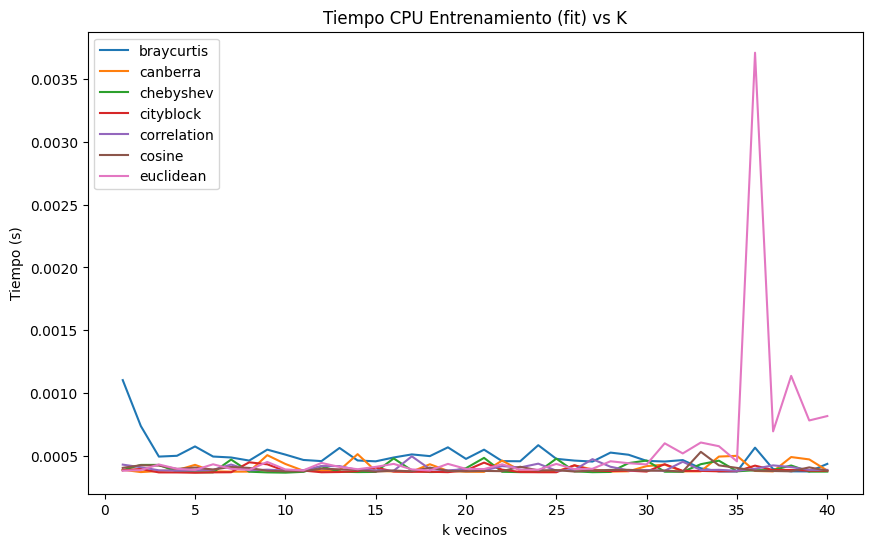

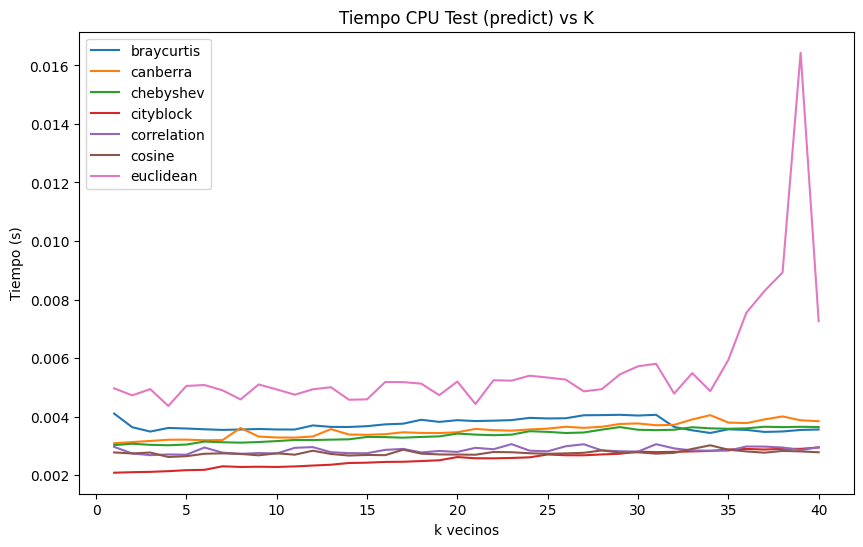

In [ ]:
import time

fig_time_fit, ax_time_fit = plt.subplots(figsize=(10, 6))
fig_time_pred, ax_time_pred = plt.subplots(figsize=(10, 6))

for metric in metricas:
    time_fit, time_pred = [], []
    
    for k in valores_k:
        knn_bc = KNeighborsClassifier(n_neighbors=k, metric=metric)
        
        # Medir tiempo fit (entrenamiento)
        t0 = time.perf_counter()
        knn_bc.fit(X_train_bc, y_train_bc)
        tf = time.perf_counter()
        time_fit.append(tf - t0)
        
        # Medir tiempo predict (test)
        t0 = time.perf_counter()
        knn_bc.predict(X_test_bc)
        tf = time.perf_counter()
        time_pred.append(tf - t0)
        
    ax_time_fit.plot(valores_k, time_fit, label=metric)
    ax_time_pred.plot(valores_k, time_pred, label=metric)

ax_time_fit.set(title='Tiempo CPU Entrenamiento (fit) vs K', xlabel='k vecinos', ylabel='Tiempo (s)')
ax_time_fit.legend()

ax_time_pred.set(title='Tiempo CPU Test (predict) vs K', xlabel='k vecinos', ylabel='Tiempo (s)')
ax_time_pred.legend()

plt.show()

e) ¿Cómo evoluciona el tiempo de CPU conforme aumenta el número de vecinos más próximos en entrenamiento y test? Razone los posibles motivos.

Cada vez que ejecuto el script, los valores cambian ligeramente, pero se mantienen las siguientes características
El tiempo de entrenamiento es casi constante y muy bajo, ya que la fase de entrenamiento en KNN es lazy learning, básicamente solo memoriza y estructura los datos en la memoria sin ajustarse a ninguna ecuación.
El tiempo de test es mayor y puede aumentar ligeramente a medida que incrementamos el número de k, pues el algoritmo debe calcular las distancias de cada muestra de test a todas las de entrenamiento, ordenarlas y luego seleccionar e inspeccionar a los k más próximos para extraer la moda.